### Práctica 5 - Análisis frecuencial de señales

#### Presentado por: Alma Olea Barbosa - Lauren Cordero Ramos 

#### Semestre: 2026-2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

4.1	Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, y utilice la frecuencia de muestreo necesaria para representarla apropiadamente. 

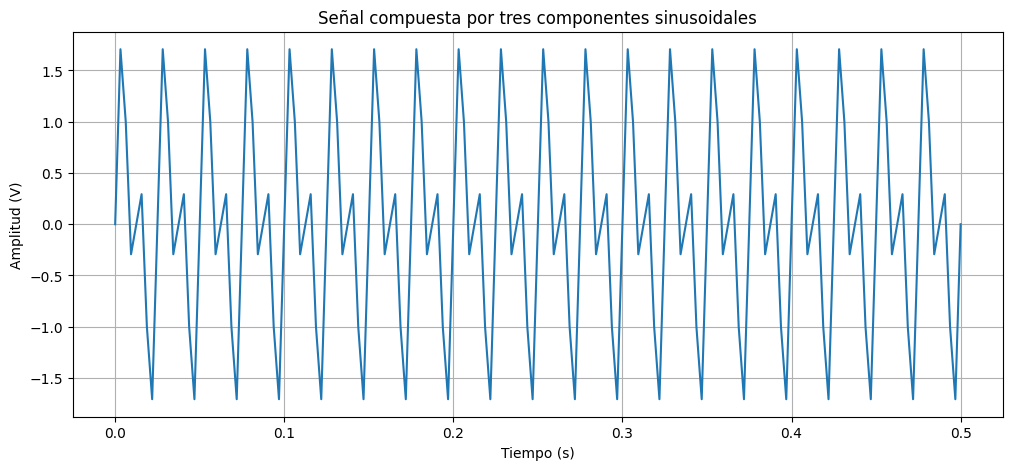

In [3]:

# Frecuencia de muestreo
fs = 2 * 160 # Teorema de Nyquist

# Periodo de muestreo
T = 1/fs

# Vector de tiempo
t = np.arange(0, 0.5+T, T)

x = (np.sin(2*np.pi*40*t)) + (np.sin(2*np.pi*80*t)) + (np.sin(2*np.pi*160*t))

# Gráfica
plt.figure(figsize=(12,5))
plt.plot(t, x)
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.title('Señal compuesta por tres componentes sinusoidales')
plt.grid()
plt.show()

4.2	Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia. Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos de la señal).

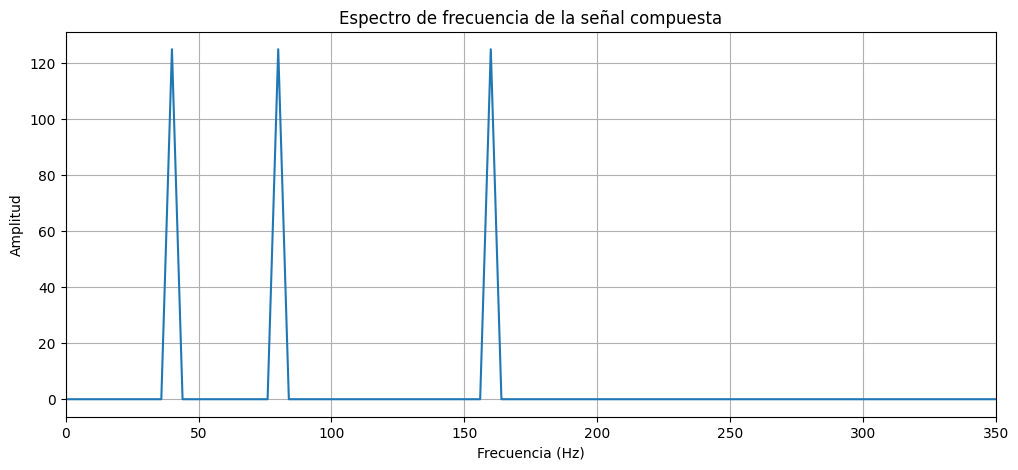

In [15]:
# Frecuencia de muestreo
Fs = 1000

# Periodo de muestreo
T = 1/Fs

# Tiempo correspondiente a 10 periodos de la frecuencia fundamental f1=40 Hz
t10 = np.arange(0, 10/40, T)

# Señal compuesta por tres componentes sinusoidales
x10 = (np.sin(2*np.pi*40*t10) +
       np.sin(2*np.pi*80*t10) +
       np.sin(2*np.pi*160*t10))

# Transformada Discreta de Fourier
X10 = np.fft.fft(x10)

# Número de muestras
N = len(X10)

# Eje de frecuencias
F = np.arange(0, N)*Fs/N

# Gráfica del espectro de frecuencia
plt.figure(figsize=(12,5))
plt.plot(F[:N//2], np.abs(X10[:N//2]))
plt.title('Espectro de frecuencia de la señal compuesta')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 350)
plt.grid()
plt.show()


4.3	Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. Aplíquelo a la señal anterior.

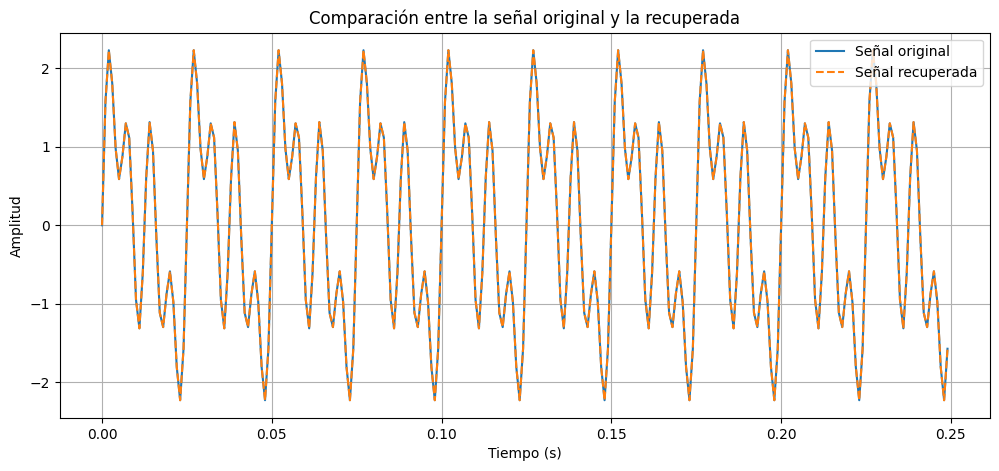

In [12]:
# Transformada Inversa de Fourier
x_r = np.fft.ifft(X10)

# Gráfica de la señal original y recuperada
plt.figure(figsize=(12,5))

plt.plot(t10, x10, label='Señal original')
plt.plot(t10, x_r.real, '--', label='Señal recuperada')

plt.title('Comparación entre la señal original y la recuperada')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()
plt.grid()
plt.show()

4.4	¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué? 

F1 = np.fft.fft(x);
F2 = np.zeros((len(F1)));
F2[9:13] = F1[9:13];
xr = np.fft.ifft(F2);
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)');
plt.show()


Es un filtro selectivo 
Sí, se puede afirmar que estas líneas de código aplican un filtro digital en el dominio de la frecuencia, específicamente un filtro que permite seleccionar y conservar determinadas componentes frecuenciales de una señal mientras que las demás se eliminan al reemplazarlas por ceros.Primero, se calcula la Transformada de Fourier para pasar la señal del dominio del tiempo al dominio de la frecuencia y luego se crea un vector de ceros en el que únicamente se conservan los valores correspondientes a las posiciones seleccionadas mediante F2[9:13]. Finalmente, se aplica la Transformada Inversa de Fourier para reconstruir la señal utilizando únicamente las frecuencias conservadas. Por esta razón, se considera un filtrado en frecuencia, porque permite conservar determinadas componentes y eliminar las demás. Más específicamente, funciona como un filtro pasabanda en el sentido de que conserva un intervalo de frecuencias, aunque la selección se realiza directamente sobre los índices de la FFT.


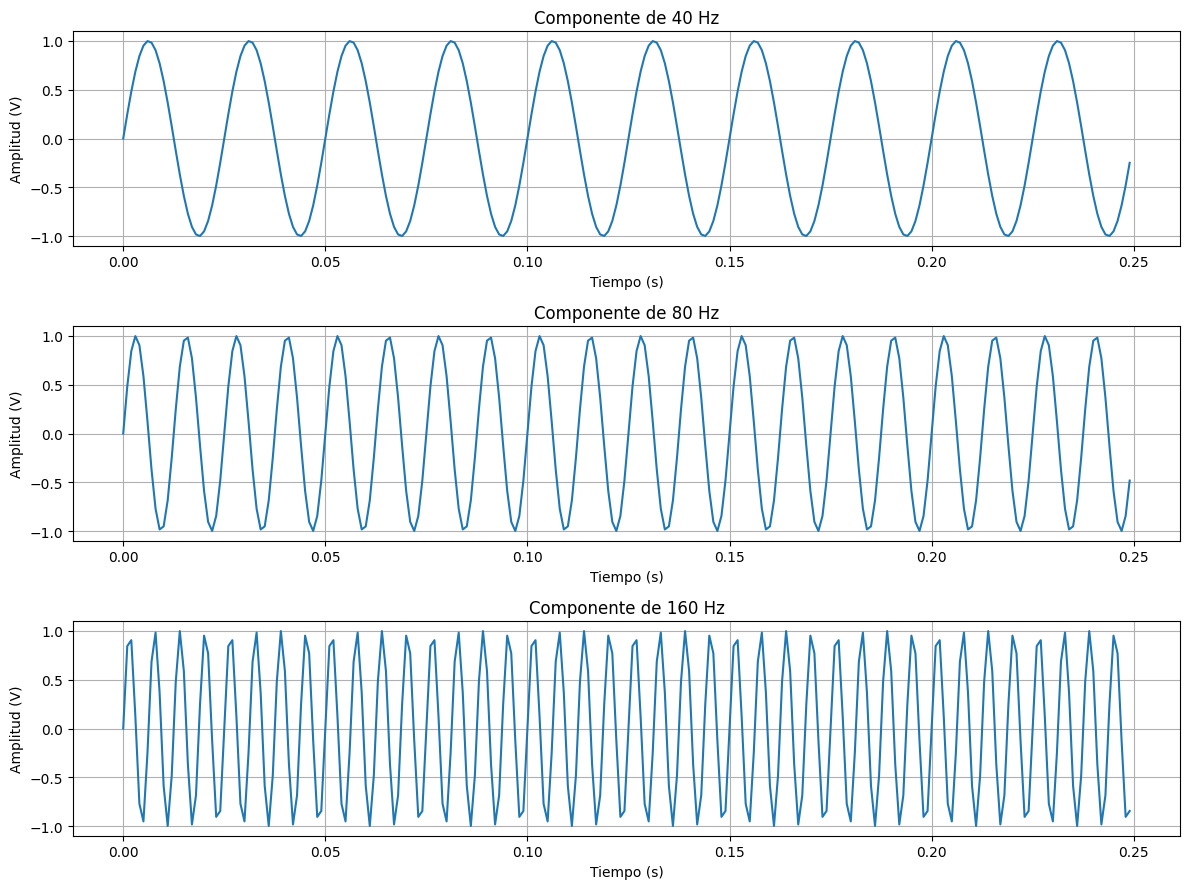

In [17]:
# Transformada de Fourier de la señal
F1 = np.fft.fft(x10)
N = len(F1)

# Índices de las frecuencias que queremos extraer
indices = [10, 20, 40]

# Frecuencias de cada componente
frecuencias = [40, 80, 160]

fig = plt.figure(figsize=(12, 9))
for i in range(3):

    # Crear vector de ceros
    F2 = np.zeros(N, dtype=complex)
    k = indices[i]
    # Conservar la frecuencia positiva y su simétrica negativa
    F2[k] = F1[k]
    F2[N-k] = F1[N-k]

    xr = np.fft.ifft(F2)

    # Graficar componente recuperada
    ax = fig.add_subplot(3, 1, i+1)
    ax.plot(t10, np.real(xr))

    ax.set(
        title=f'Componente de {frecuencias[i]} Hz',
        xlabel='Tiempo (s)',
        ylabel='Amplitud (V)'
    )

    ax.grid()
plt.tight_layout()
plt.show()

4.5	Cree una función que calcule manualmente el periodograma de Welch de una señal discreta (usando la DFT), explique paso a paso el algoritmo. Pruébelo e una de las señales construidas anteriormente.

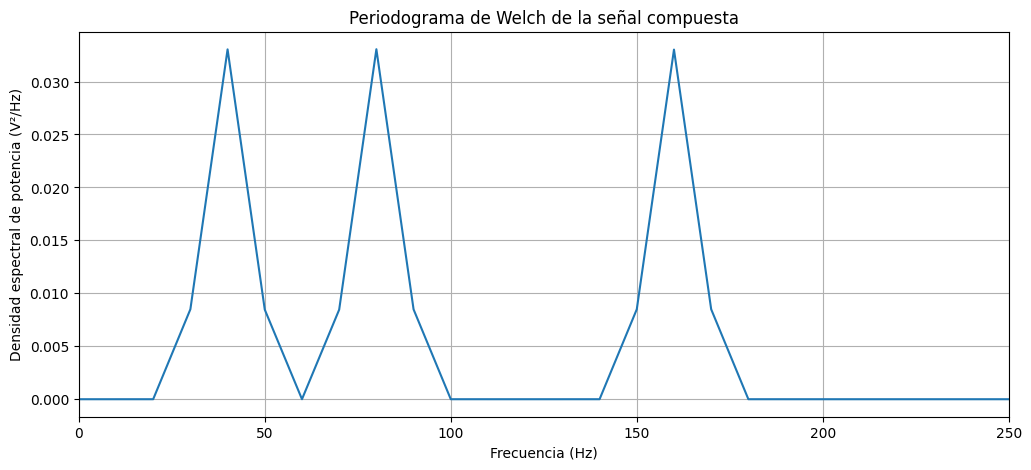

In [ ]:
def welch_manual(x, Fs, nperseg):

    # Paso 1: Dividir la señal en segmentos
    N = len(x)
    paso = nperseg // 2  # Solapamiento del 50%
    segmentos = []
    
    for i in range(0, N - nperseg + 1, paso):
        segmento = x[i:i+nperseg]
        segmentos.append(segmento)

    # Paso 2: Aplicar ventana de Hanning a cada segmento
    ventana = np.hanning(nperseg)

    # Paso 3: Calcular la DFT de cada segmento y su periodograma
    periodogramas = []
    for segmento in segmentos:
        segmento = segmento * ventana
        X = np.fft.rfft(segmento)
        P = (np.abs(X)**2) / (Fs * np.sum(ventana**2))

        # Duplicar las componentes positivas interiores
        if nperseg % 2 == 0:
            P[1:-1] *= 2
        else:
            P[1:] *= 2

        periodogramas.append(P)

    # Paso 4: Promediar los periodogramas
    P_welch = np.mean(periodogramas, axis=0)

    # Paso 5: Calcular el eje de frecuencias
    F = np.fft.rfftfreq(nperseg, d=1/Fs)
    return F, P_welch


# Aplicar el método de Welch a la señal construida anteriormente
F_welch, P_welch = welch_manual(x10, Fs, 100)

# Graficar el resultado
plt.figure(figsize=(12,5))
plt.plot(F_welch, P_welch)
plt.title('Periodograma de Welch de la señal compuesta')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Densidad espectral de potencia (V²/Hz)')
plt.xlim(0, 250)
plt.grid()
plt.show()

El método de Welch es una técnica utilizada para estimar la densidad espectral de potencia de una señal discreta. Su funcionamiento consiste en dividir la señal en varios segmentos, aplicar una ventana a cada uno de ellos y calcular su Transformada Discreta de Fourier (DFT). Posteriormente, se obtiene el periodograma de cada segmento y se promedian los resultados para conseguir una estimación más estable del contenido frecuencial de la señal [1].
Para implementar este método, se creó una función en Python que realiza manualmente cada uno de estos pasos, utilizando las funciones de NumPy para el procesamiento de las señales. La función se probó con la señal compuesta por tres componentes sinusoidales de 40 Hz, 80 Hz y 160 Hz. Como resultado, se obtuvo una gráfica de densidad espectral de potencia en la que se identifican las tres frecuencias, comprobando el funcionamiento del método de Welch.

En este ejercicio se utilizó una ventana de Hanning, segmentos de 100 muestras y un solapamiento del 50 %.

4.6	El archivo adjunto (senecg.mat) contiene una señal de ECG adquirida a una frecuencia de muestreo de 250 Hz. Realice un análisis en frecuencia de la señal usando periodogramas de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que se mostró antes y compruebe que lo haya realizado, calcule la transformada inversa de Fourier de la señal filtrada y compruebe con el periodograma. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventaja) (25%). Compare el método de la librería con la función creada en el punto anterior.

4.7	Realice un análisis de frecuencia a través del periodograma de welch de una señal de EKG de un paciente Sano y otra de un paciente con alguna condición cardiaca que en el proyecto 1 hayan identificado que presentaba diferencias, si no encontró diferencias, elija un par al azar. Realice un análisis comparativo de las señales según lo que le indiquen los periodogramas. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventaja)

### Conclusiones 

### Referencias

[1] P. D. Welch, “The use of fast Fourier transform for the estimation of power spectra: A method based on time averaging over short, modified periodograms,” IEEE Transactions on Audio and Electroacoustics, vol. AU-15, no. 2, pp. 70–73, Jun. 1967, doi: 10.1109/TAU.1967.1161901.